# 03 · Stage 3 — Constraints

Stage 3 takes the imputation run of Stage 2 (a prior $a_0$ with its σ for every edge) and returns, for each year, the constraint rows $G$, $c$, $\sigma_c$ that the reconciled flows must satisfy: exactly where a row is hard, approximately where it is soft.

> **What this stage assumes**
> - **A3** Hard rows hold exactly; soft rows are priced by $\sigma_c^{-2}$ (Eq. 2).
> - **A4** One QP per period: no row couples two years, enforced when `G` is built.
> - **A8** An edge with no data keeps its noisy zero as the prior mean; Stage 3 gives it a σ that makes the zero count.
> - **A10** A satellite flow carries a value but sits outside its node's balance.
> - Copper's choice: its rows also include prior-anchored scale totals (ADR 0006) and hard bands, among them the non-negativity of every flow (ADR 0039); the toy has neither (manuscript Table 2, §3.1.6).

In [1]:
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

from pysuto import acc_store
from pysuto.tutorial import toy
from pysuto.diag import ConstDiagnostic, ConstStatsDiagnostic
from pysuto.registry import ConstraintRunRegistry, ImputationRunRegistry

RUNS = Path("runs")
PROC = RUNS / "proc"
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 70)
logging.disable(logging.INFO)

Chapters 01 and 02 left feed runs and an imputation run in `runs/`. This chapter runs only Stage 3 on top of them. The toy declares its own labels (`Gross`, `Content`), has no hard bands, and lives in a closed world without `ROW`; the stage does not care about the first or the third.

## The run we are reading

In [2]:
const_id = toy.run_stage3(RUNS)
const = ConstraintRunRegistry(str(PROC / "const")).load(const_id)
rm = const.row_meta
acc = acc_store.load("toy", storage_dir=str(PROC / "acc"))
em = acc.edge_meta.set_index("edge_id")
em["edge"] = acc.edge_labels()
print(const_id)
print(f"G: {const.G.shape[0]} rows × {const.G.shape[1]} edges, {len(const.timestep_data)} years, "
      f"{len(rm) // len(const.timestep_data)} rows per year")

const_20261123_171614_ce3017f9
G: 410 rows × 420 edges, 5 years, 82 rows per year


A row is one linear statement about edges, $G_k a = c_k$, with a spread $\sigma_{c,k}$. `row_meta` says what each row is; we read its columns and never parse a `constraint_id`. Here is one year, 2003, by family.

In [3]:
year = "2003"
r3 = rm[rm["time"].astype(str) == year]
r3.groupby(["type", "variant", "is_hard"]).size().rename("rows").to_frame()

rows
type    variant               is_hard      
massbal massbal               True       36
ratio   concconcentratesupply False       9
        concconcentrateuse    False       3
        concmetalsupply       False       6
        concmetaluse          False       3
        concoresupplyisla     False       1
        concoresupplymontara  False       1
        concoreuseisla        False       1
        concoreusemontara     False       1
        concscrapsupply       False       3
        concslaguse           False       3
        conctailingsuse       False       3
        concwasterockuse      False       3
        effmilling            False       3
        effsmelting           False       3
        strippingratio        True        3

Two types: `massbal` and `ratio`. The next four sections take them in turn.

## Hard mass balances

Every Process and Flow node must balance, per region, year and valuation: what comes in equals what goes out. One row each, $\sigma_c = 0$. Here is Montara's Mining in 2003 (`Gross`), and its smelter in Portua (`Content`).

In [4]:
def row_edges(i):
    r = const.G[i].tocoo()
    return pd.DataFrame({"edge": [em.at[c, "edge"] for c in r.col], "coef": r.data})

pick = (rm["type"] == "massbal") & (rm["time"].astype(str) == year)
i_mine = int(np.flatnonzero(pick & (rm["sector"] == "Mining") & (rm["region"] == "Montara")
                            & (rm["valuation"] == "Gross"))[0])
i_smelt = int(np.flatnonzero(pick & (rm["sector"] == "Smelting") & (rm["region"] == "Portua")
                             & (rm["valuation"] == "Content"))[0])
display(row_edges(i_mine))
display(row_edges(i_smelt))

,edge,coef
0,Deposit|Montara → Mining|Montara (Gross),1.0
1,Mining|Montara → Ore|Montara (Gross),-1.0


,edge,coef
0,Concentrate|Montara → Smelting|Portua (Content),1.0
1,Concentrate|Portua → Smelting|Portua (Content),1.0
2,Concentrate|Isla → Smelting|Portua (Content),1.0
3,Smelting|Portua → Metal|Portua (Content),-1.0
4,Smelting|Portua → Slag|Portua (Content),-1.0
5,Scrap|Portua → Smelting|Portua (Content),1.0


Inflows $+1$, outflows $-1$, right-hand side 0. The smelter row pools every input (three concentrate legs and scrap) against its metal and slag. The Mining row has one edge in and one out, and the edge `Mining → WasteRock` is *not* in it. Waste rock is a satellite (A10): it carries a value, tied to ore by the stripping relation below, but sits outside Mining's balance. The accounting structure says so with a mask, `massbal_scope`, which the mass-balance builder reads.

In [5]:
mine_edges = em[(em["from_sector"] == "Mining") & (em["from_region"] == "Montara")
                & (em["valuation"] == "Gross") & (em["time"] == year)]
print(*mine_edges["edge"], sep="\n")
print("rows of the Mining balance that touch WasteRock:",
      int(row_edges(i_mine)["edge"].str.contains("WasteRock").sum()))

Mining|Montara → Ore|Montara (Gross)
Mining|Montara → WasteRock|Montara (Gross)
rows of the Mining balance that touch WasteRock: 0


## Soft ratio rows

A ratio row ties two edges, or two pooled sums of edges, by a parameter: $a_i - r\,a_j = \varepsilon$. The parameters live in registered CSVs (chapter 02 read the same ones). The toy has two kinds.

A `conc` row says an edge's content is a grade times its gross mass. Isla's smelter takes Isla's concentrate in 2003:

In [6]:
i_conc = int(np.flatnonzero((rm["variant"] == "concconcentratesupply") & (rm["time"].astype(str) == year)
                            & (rm["num_region_from"] == "Isla") & (rm["num_region_to"] == "Isla"))[0])
td = const.timestep_data[year]
print(row_edges(i_conc).to_string(index=False))
print(f"c = {td['c'][i_conc]:.1f}   σ_c = {td['sigma_c'][i_conc]:.4f}   hard: {bool(rm.at[i_conc, 'is_hard'])}")

                                      edge  coef
  Concentrate|Isla → Smelting|Isla (Gross) -0.28
Concentrate|Isla → Smelting|Isla (Content)  1.00
c = 0.0   σ_c = 0.1561   hard: False


Content minus $0.28 \times$ gross equals a small $\varepsilon$ the solver may spend, at a price of $1/\sigma_c^2$. The σ comes from the parameter's own uncertainty. An `eff` row ties a process's output to its pooled input by its recovery. Smelting in Isla:

In [7]:
i_eff = int(np.flatnonzero((rm["variant"] == "effsmelting") & (rm["time"].astype(str) == year)
                           & (rm["region"] == "Isla"))[0])
print(row_edges(i_eff).to_string(index=False))
print(f"c = {td['c'][i_eff]:.1f}   σ_c = {td['sigma_c'][i_eff]:.4f}")

                                         edge  coef
Concentrate|Montara → Smelting|Isla (Content) -0.97
 Concentrate|Portua → Smelting|Isla (Content) -0.97
   Concentrate|Isla → Smelting|Isla (Content) -0.97
         Smelting|Isla → Metal|Isla (Content)  1.00
         Scrap|Isla → Smelting|Isla (Content) -0.97
c = 0.0   σ_c = 0.0823


Metal out minus $0.97 \times$ (all concentrate in, scrap included). That pooling is set in the parameter row (`agg=true`), never inferred (ADR 0005): without it, scrap would be an unrecovered input. It is the same recipe as chapter 02's reverse efficiency, now as a row rather than a fill.

## The hard stripping relation

Waste rock is outside the balance, so it needs its own rule: waste rock $= k \times$ ore, $k = 2$ (`stripping_ratio`, ADR 0038). The toy makes it **hard**.

In [8]:
i_strip = int(np.flatnonzero((rm["variant"] == "strippingratio") & (rm["time"].astype(str) == year)
                             & (rm["num_region_from"] == "Isla"))[0])
print(row_edges(i_strip).to_string(index=False))
print(f"c = {td['c'][i_strip]:.1f}   σ_c = {td['sigma_c'][i_strip]:.1f}   hard: {bool(rm.at[i_strip, 'is_hard'])}")

                                edge  coef
      Mining|Isla → Ore|Isla (Gross)  -2.0
Mining|Isla → WasteRock|Isla (Gross)   1.0
c = 0.0   σ_c = 0.0   hard: True


$\sigma_c = 0$: a hard row. Hard and soft are one property of the row, $\sigma_c = 0$ or $> 0$ (A3). Across the year:

In [9]:
sc = np.asarray(td["sigma_c"])[r3.index]
print(pd.Series({"hard rows, σ_c": sc[r3["is_hard"].to_numpy().astype(bool)].max(),
                 "soft rows, smallest σ_c": sc[~r3["is_hard"].to_numpy().astype(bool)].min(),
                 "soft rows, largest σ_c": sc[~r3["is_hard"].to_numpy().astype(bool)].max()}).to_string())

hard rows, σ_c               0.000000
soft rows, smallest σ_c      0.020312
soft rows, largest σ_c     476.484771


## The no-data anchor

Chapter 02 ended with edges at a noisy zero, σ $= 10^6$ kt. At that σ the pull of the prior, $(a - 0)^2 / \sigma_a^2$, is nil: the edge is free slack, a place where the solver can hide any contradiction. Stage 3 re-anchors such an edge: the mean stays 0, but σ becomes a small share of the typical size of the edge's siblings (A8, ADR 0013).

In [10]:
imp_id = json.loads((PROC / "const" / const_id / "metadata.json").read_text())["parents"]["upstream"]["imp_run_id"]
imp = ImputationRunRegistry(str(PROC / "imp")).load(imp_id)
ilog = imp.imputation_log.as_dataframe()
flat = em.loc[ilog.loc[ilog["method"] == "flat_prior_noisy_zero", "edge_id"]].copy()
flat["σ Stage 2 (kt)"] = imp.sigma_agg[flat.index]
flat["σ_a Stage 3 (kt)"] = const.sigma_a[flat.index]
flat["a₀ (kt)"] = const.a0[flat.index]
flat.groupby(["from_sector", "valuation"])[["σ Stage 2 (kt)", "σ_a Stage 3 (kt)", "a₀ (kt)"]].first()

σ Stage 2 (kt)  σ_a Stage 3 (kt)  a₀ (kt)
from_sector valuation                                           
Concentrate Content         1000000.0          0.084576      0.0
            Gross           1000000.0          0.302056      0.0
Deposit     Gross           1000000.0         30.789319      0.0
Mining      Gross           1000000.0         43.230050      0.0
Ore         Gross           1000000.0         33.659379      0.0

Same zero, a σ of the order of the neighbouring flows instead of a million. A hard balance can still force flow through such an edge, but at a price. Copper spares its extraction chain from this anchor where a grade row sets its magnitude (ADR 0013 amendment 3); the toy's only no-data edges are Portua's mine-less chain and the concentrate legs nobody reports, and none of them has a relation to defend, so none is spared.

<details><summary>Going deeper: how the anchor σ is set</summary>

For each group of no-data edges with the same sending sector and valuation, ADR 0013 sets
$\sigma = \max\bigl(\text{floor},\; \mathrm{cv} \cdot \operatorname{median}|a_0|\text{ of the anchored siblings}\bigr)$ with $\mathrm{cv}$ = `NODATA_ANCHOR_CV`. "Anchored" means a non-zero prior. The cell after the box prints the ratio of $\sigma_a$ above to that median; it is the knob, 0.05.

The mean stays 0. A flat σ, which would ignore size, would anchor the 1000-kt ore edges and the 0.1-kt content edges equally loosely or equally tightly; siblings give each sector its own scale. Before the anchor, the σ of such an edge came from the global median of a flow of the account, which in copper was about $10^6$ kt: no pull at all. The anchor is soft: unlike the zero pin of the same ADR, it never makes a problem infeasible.
</details>

In [11]:
sib = pd.Series({k: np.median(np.abs(const.a0[em.index[(em["from_sector"] == k[0])
                                                       & (em["valuation"] == k[1])
                                                       & (np.abs(const.a0) > 1e-9)]]))
                 for k in flat.groupby(["from_sector", "valuation"]).groups})
ratio = flat.groupby(["from_sector", "valuation"])["σ_a Stage 3 (kt)"].first() / sib
print(ratio.round(3).to_string())
print("NODATA_ANCHOR_CV of this run:", json.loads((PROC / "const" / const_id / "metadata.json").read_text())["stage_config"]["nodata_anchor_cv"])

from_sector  valuation
Concentrate  Content      0.05
             Gross        0.05
Deposit      Gross        0.05
Mining       Gross        0.05
Ore          Gross        0.05
NODATA_ANCHOR_CV of this run: 0.05


## G by year

$G$ has 410 rows and 420 columns, but a row only ever touches the edges of its own year. Ordered by year, it is block-diagonal; `ConstDiagnostic` draws one year's block.

In [12]:
by_year = pd.DataFrame({t: {"rows": int((rm["time"].astype(str) == t).sum()),
                            "edges": len(const.edge_cols_by_t[t]),
                            "non-zeros": int(const.G_blocks[t].nnz)}
                        for t in const.timestep_data}).T
by_year

,rows,edges,non-zeros
2001,82,84,221
2002,82,84,221
2003,82,84,221
2004,82,84,221
2005,82,84,221


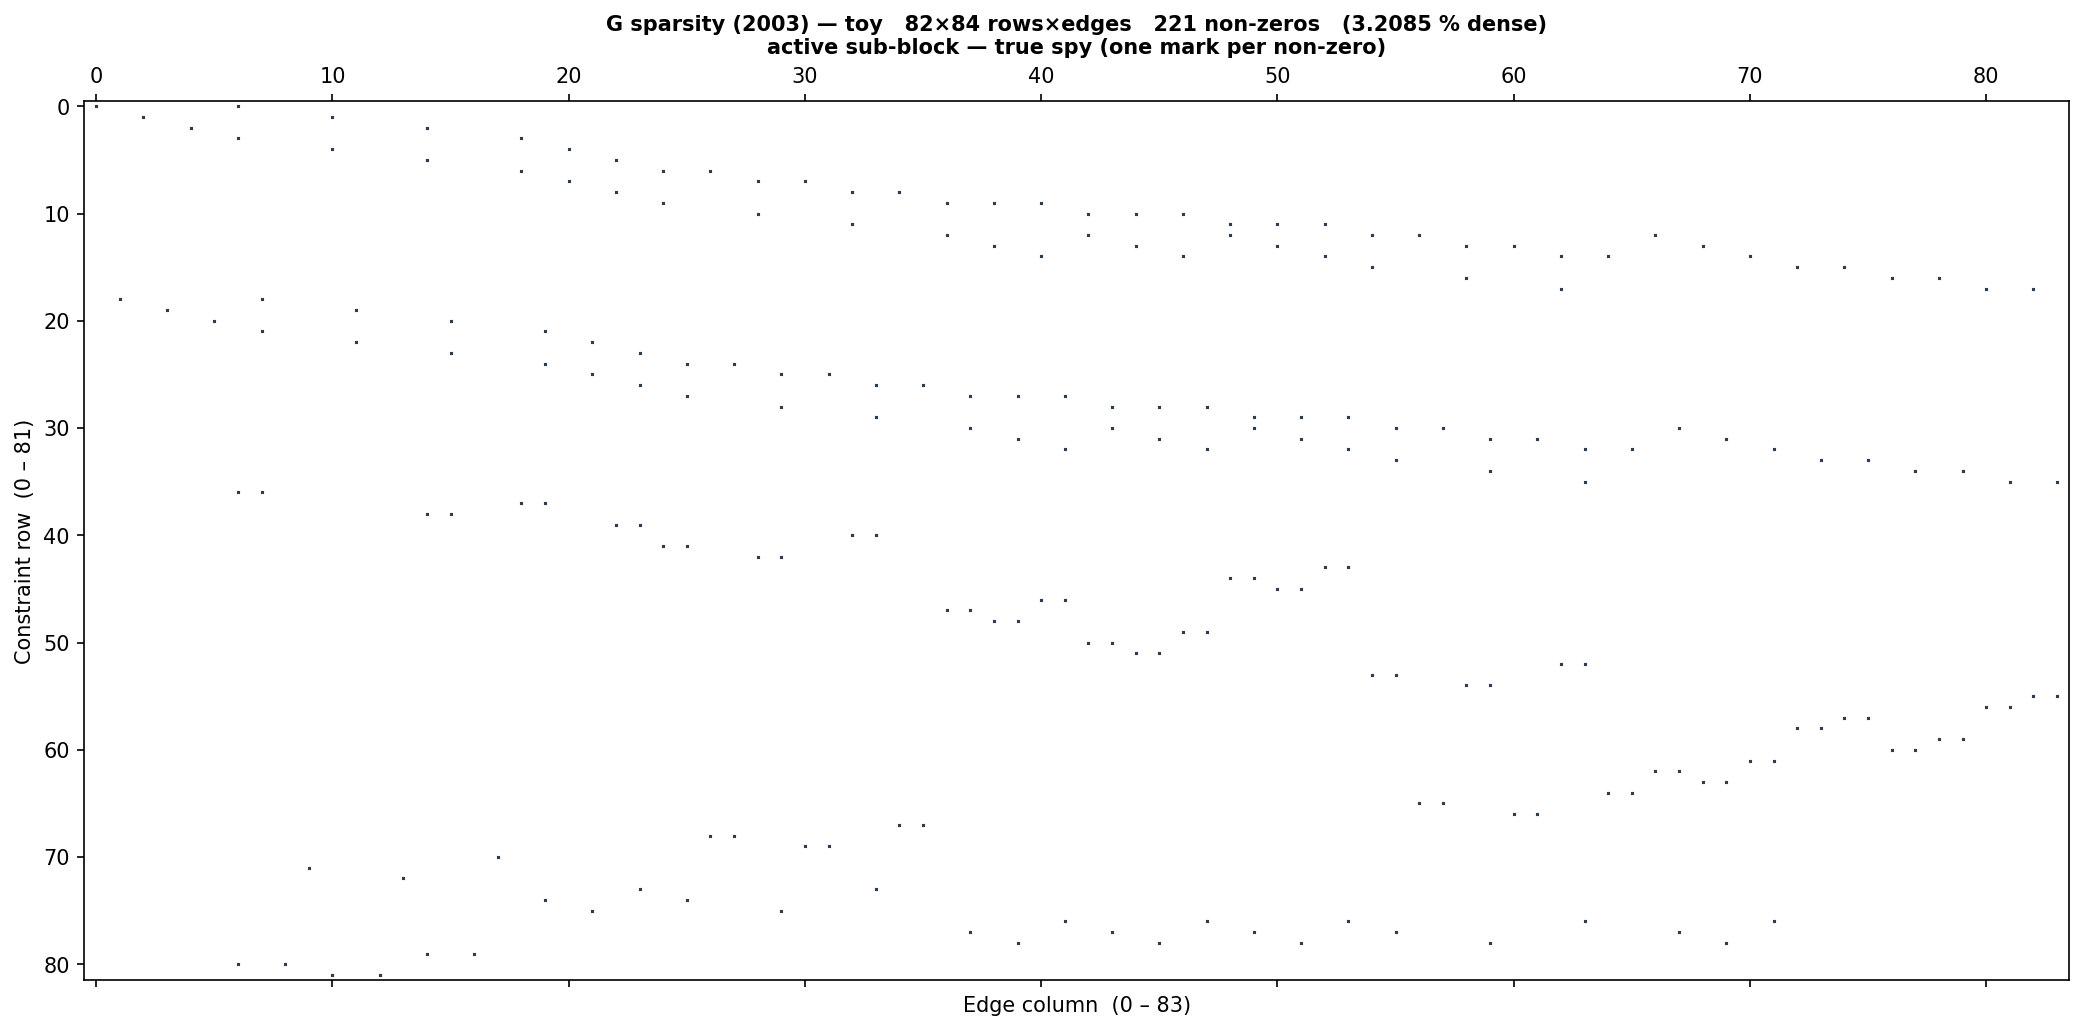

In [13]:
FIGS = RUNS / "figs"
FIGS.mkdir(parents=True, exist_ok=True)
diag = ConstDiagnostic.from_saved(str(PROC / "const" / const_id), label="toy", year=year)
diag.plot(odir=str(FIGS), show=False)
display(Image(str(FIGS / "fig1_G_sparsity.png")))

Each dot is a non-zero: at most six per row, a few per cent of the block. Now check the claim of A4 directly. Take the rows of 2003 and ask whether any of them is non-zero on an edge of another year.

In [14]:
cols_t = np.asarray(const.edge_cols_by_t[year])
outside = np.setdiff1d(np.arange(const.G.shape[1]), cols_t)
rows_t = r3.index.to_numpy()
print(f"{year}: {len(rows_t)} rows, {len(cols_t)} edges; non-zeros outside its own edges: "
      f"{int((const.G[rows_t][:, outside] != 0).sum())}")

2003: 82 rows, 84 edges; non-zeros outside its own edges: 0


None. That is what lets Stage 4 solve five small QPs instead of one large one, and Stage 3 refuses to build a `G` where it is false (`_partition_G_by_time` raises on any cross-year non-zero).

<details><summary>Going deeper: what `G` stores</summary>

`G` is a CSR matrix built from coordinate triplets. It stores explicit zeros: the concentration row of waste rock has grade 0 and still occupies a position. So `G.nnz` over-counts the non-zero coefficients. The next cell compares the two; count with `G != 0` whenever the number matters.

The engine keeps, besides the whole `G`, the per-year blocks `G_blocks[t]` and the column lists `edge_cols_by_t[t]` that the solver reads. Rows are year-local by construction, and a row whose `time` is no year of the accounting structure raises: no row is silently left out of every block.
</details>

In [15]:
print(f"stored entries {const.G.nnz}; non-zero coefficients {int((const.G != 0).sum())}")

stored entries 1105; non-zero coefficients 1090


## The prior constraint table

Before any solve, the prior already says how well it satisfies each row: the **residual** $G a_0 - c$ and, on soft rows, the z-score $(G a_0 - c)/\sigma_c$. `ConstStatsDiagnostic` builds that table for the years you ask for.

In [16]:
table = ConstStatsDiagnostic(const, years=(year,)).constraint_table(year)
hard = table["is_hard"].astype(bool)
print(f"hard rows: {int(hard.sum())}, of which the prior breaks {int((table.loc[hard, 'residual_abs'] > 1e-6).sum())} "
      f"(largest |residual| {table.loc[hard, 'residual_abs'].max():.2f})")
print(f"soft rows: {int((~hard).sum())}, with |z| > 3 at the prior: {int((table.loc[~hard, 'z_abs'] > 3).sum())}")

hard rows: 39, of which the prior breaks 23 (largest |residual| 23801.76)
soft rows: 43, with |z| > 3 at the prior: 2


The prior is made of noisy observations and fills, so it does not balance: more than half of the hard rows are broken by it. Making it balance is the solver's job. Soft rows tell a different story, because most of them were *built* from the prior (a fill is a ratio of its source), so they start near zero. Largest soft rows first:

In [17]:
soft = table[~hard].sort_values("z_abs", ascending=False)
soft[["variant", "valuation", "lhs_prior", "c", "sigma_c", "z"]].head(5)

,variant,valuation,lhs_prior,c,sigma_c,z
78,effsmelting,Content,-6.464790e+03,0.0,129.483778,-4.992742e+01
76,effsmelting,Content,5.270348e-01,0.0,0.082266,6.406476e+00
56,concmetalsupply,Content,-4.440892e-16,0.0,0.077246,-5.749033e-15
77,effsmelting,Content,1.110223e-16,0.0,0.045272,2.452323e-15
40,concconcentrateuse,Content,-4.440892e-16,0.0,0.193019,-2.300755e-15


One row is far above the rest: a smelting recovery row of one region. At the prior, that region's metal and its pooled input differ by more than the recovery $r$ can explain, by tens of $\sigma_c$ (the table's `z`). Nothing in Stage 3 can say whether the recovery parameter, the prior of an input edge, or the metal is at fault; we leave the row for chapter 04 and carry on.

## What the toy does not have

**No scale totals.** The `type` column of this run holds two values.

In [18]:
print(sorted(rm["type"].unique()))

['massbal', 'ratio']


Copper adds a third, `sum`: a **scale total** per process and per flow that pins the node's total output to the model's own prior, $\sum a = \sum f_{\text{agg}}$, as a soft row at about 1 % (ADR 0006). It exists to stop the whole account from shrinking together when feeds are sparse. The toy has no such total, and for an honest reason: a prior-anchored total *restates the prior*, and at 1 % it restates an erroneous prior as firmly as a good one. On the toy, whose prior carries one deliberate error, such a row became the loudest soft residual of the run and cut Stage 5's coverage; chapter 08 shows it break. The toy's own first draft carried the automatic sum rows; they only repeated the hard balances and did nothing, so they are gone. The toy therefore leans on the balances and the ratio rows alone.

**No bands.** Copper's QP carries a third group of rows, hard inequalities: the pooled recovery bands, and one row $-a_i \le 0$ for every edge whose structural lower bound is zero (ADR 0039). The toy registers neither. How many rows that last family would add here?

In [19]:
lower = np.asarray(acc.bounds.l)
print(f"edges with lower bound 0: {int((lower == 0).sum())} of {len(lower)}; "
      f"signed (below 0): {int((lower < 0).sum())}  → {int((lower == 0).sum()) // 5} bound rows a year")

edges with lower bound 0: 390 of 420; signed (below 0): 30  → 78 bound rows a year


Every edge but the signed stock change `Metal → Stock`. The toy's QP has equality rows only, and a posterior flow may therefore come out below zero; the toy accepts that and says so. What it buys is a posterior with no active set to choose, so its intervals can be scored against the truth.

**A closed world.** There is no `ROW` region, so none of copper's rest-of-the-world rows exist.

**Exercise 3.1** — Count the hard and the soft rows of 2003 from `row_meta`, using the family table shown at the top of the chapter as your guide, and check them with `toy.check_3_1`. Cover the next cell and try it first; `toy.solution("3.1")` prints the reference.

In [20]:
rows = rm[rm["time"].astype(str) == "2003"]
n_hard = int(rows["is_hard"].sum())
print(toy.check_3_1(RUNS, n_hard, len(rows) - n_hard))

✓ 3.1  2003 has 39 hard and 43 soft rows


## Where this run came from

In [21]:
meta = json.loads((PROC / "const" / const_id / "metadata.json").read_text())
print("parents.inputs  :", {k: (v if isinstance(v, dict) else [x["id"] + " v" + str(x["version"]) for x in v])
                            for k, v in meta["parents"]["inputs"].items()})
print("parents.upstream:", meta["parents"]["upstream"])

parents.inputs  : {'acc': {'id': 'toy', 'version': 1, 'date': '2026-11-23T17:15:56Z', 'code': '3e661eae', 'label': 'toy'}, 'params': ['conc v1', 'eff v1', 'stripping_ratio v1']}
parents.upstream: {'imp_run_id': 'imp_20261123_171602_87bc50df'}


The constraint run names the imputation run it was built on, and the accounting structure and parameters it read. Next: [chapter 04](04_solver.ipynb), where one QP per year makes the prior satisfy the rows.